In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

house_df = pd.read_csv('kc_house_data.csv')

## Exercise 1
a) Create and train simple regression model of sqft_living to price.  
b) Evaluate and visualise created model.  
c) Create and plot higher order polynomial regression models.

In [48]:
#a)

X = house_df.sqft_living.values.reshape(-1, 1)[:1000]
y = house_df.price.values.reshape(-1)[:1000]

model = LinearRegression()
model.fit(X, y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 1)
y shape: (1000,)


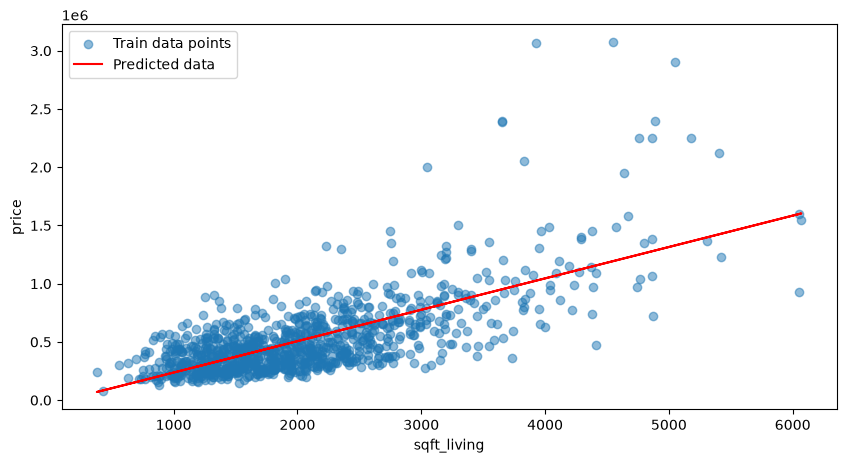

In [49]:
#b)

#Your code:
y_pred = model.predict(X)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X, y, label="Train data points", alpha=0.5)
ax.set_xlabel("sqft_living")
ax.set_ylabel("price")
ax.plot(X, y_pred, label="Predicted data", color="red")
ax.legend()

#Hint: model.predict(), model.intercept_,  model.coef_, model.score()

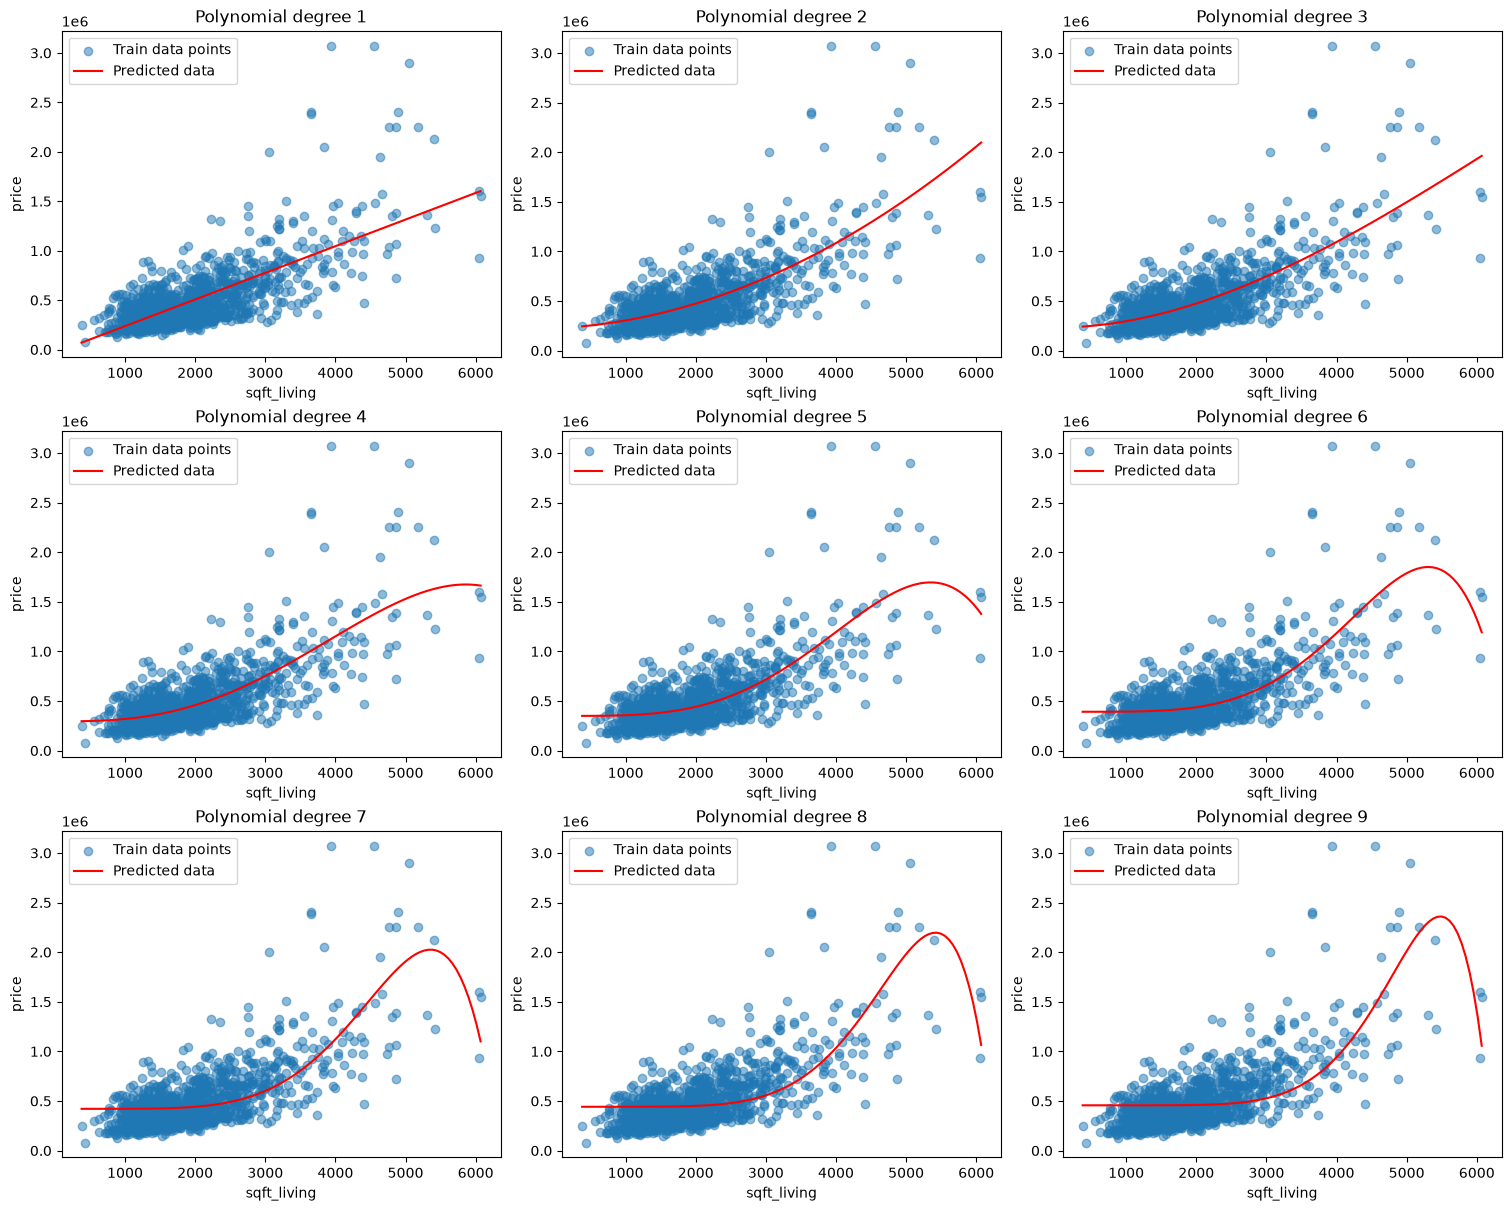

In [50]:
#c)
N = 9
fig, axes = plt.subplots(3, 3, figsize=(15, 12), constrained_layout=True)

X_pred = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

for order, ax in enumerate(axes.flat, start=1):
    poly = PolynomialFeatures(order, include_bias=False)
    X_order = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_order, y)

    y_pred = model.predict(poly.transform(X_pred))

    ax.scatter(X, y, label="Train data points", alpha=0.5)
    ax.plot(X_pred, y_pred, label="Predicted data", color="red")
    ax.set_title(f"Polynomial degree {order}")
    ax.set_xlabel("sqft_living")
    ax.set_ylabel("price")
    ax.legend()

plt.show()


House prices generally increase with living area, but houses of similar size can still have very different prices. Living area alone therefore cannot explain all the variation. The linear model captures the overall trend, while polynomial features allow the fitted relationship to curve.

A higher polynomial degree makes the model more flexible, but a curve that follows the training points more closely is not necessarily better at predicting new houses. This exercise fits and plots the same 1,000 houses, so the plots alone do not measure performance on unseen data.


## Exercise 2
In reality, we are not given the full dataset, so we need to create models which are able to handle unknown data.  
a) Split your data into training sample and test sample and repeat exercise 1 c). Plot training and test errors for all models. 

Min test error:  244777.13888669646


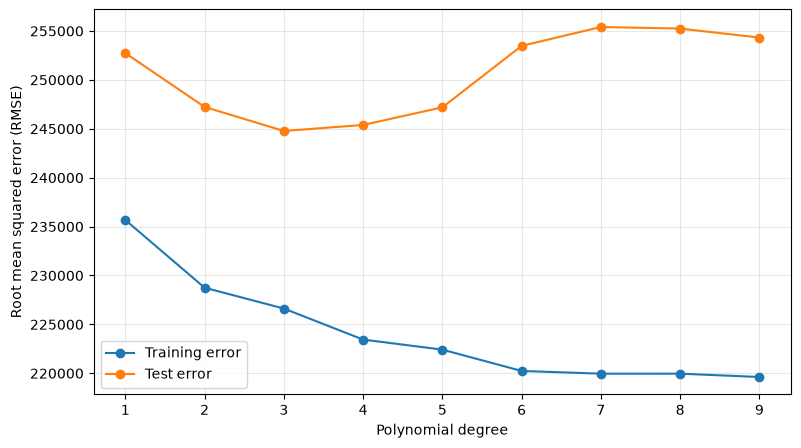

In [51]:
#a)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=44
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

degrees = range(1, N + 1)
train_errors = []
test_errors = []

for order in degrees:
    poly = PolynomialFeatures(order, include_bias=True)
    X_train_poly = poly.fit_transform(X_train, y_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    train_errors.append(np.sqrt(mean_squared_error(y_train, train_pred)))
    test_errors.append(np.sqrt(mean_squared_error(y_test, test_pred)))

print("Min test error: ", min(test_errors))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(degrees, train_errors, "o-", label="Training error")
ax.plot(degrees, test_errors, "o-", label="Test error")
ax.set_xlabel("Polynomial degree")
ax.set_ylabel("Root mean squared error (RMSE)")
ax.set_xticks(degrees)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

On this split, degree 3 gives the lowest test RMSE, approximately $244,777. Higher degrees produce larger test errors, so increasing complexity does not keep improving predictions.

Comparing degrees using this test split effectively uses it as validation data. A separate test set would be needed for an independent final evaluation after choosing the degree, as demonstrated in Exercise 3.


## Exercise 3
a) Train model to predict sqft_living for a given house price. Plot predictions.  
b) Apply more features and propose better model for predicting house prices. Try to beat proposed one.

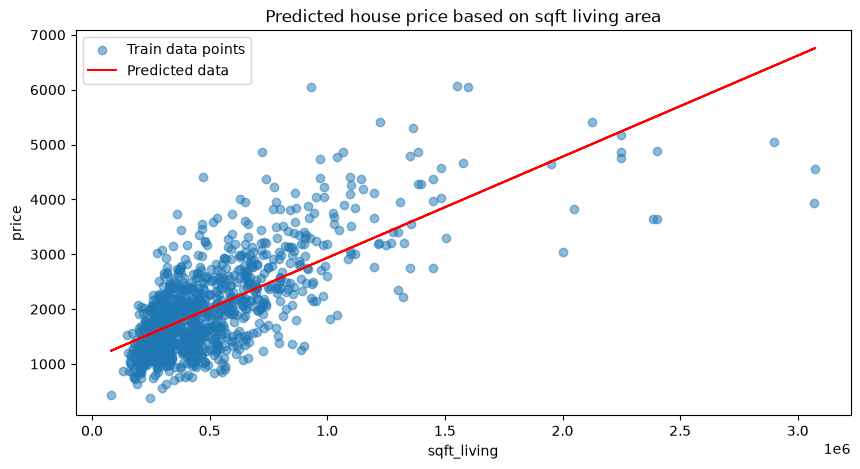

In [52]:
#a)

X = house_df.price.values.reshape(-1, 1)[:1000]
y = house_df.sqft_living.values.reshape(-1)[:1000]

#Your code:
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X, y, label="Train data points", alpha=0.5)
ax.plot(X, y_pred, label="Predicted data", color="red")
ax.set_xlabel("sqft_living")
ax.set_ylabel("price")
ax.legend()
plt.title("Predicted house price based on sqft living area")
plt.show()

In [53]:
# b) Compare both models on the same training / validation / test rows.

# About 60% training, 20% validation, 20% test.
train_val_df, test_df = train_test_split(
    house_df, test_size=0.2, random_state=43
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.25, random_state=43
)

old_features = ['sqft_living', 'sqft_lot', 'grade', 'view']
features = [
    'sqft_living', 'grade', 'bathrooms', 'lat', 'long',
    'view', 'waterfront', 'sqft_living15', 'condition', 'yr_built',
]
candidates = {
    'Old model': (old_features, 3),
    'New model': (features, 2),
}

# Fit on training data, compare on validation data without using the test set.
validation_errors = {}
for name, (columns, degree) in candidates.items():
    poly = PolynomialFeatures(degree, include_bias=False)
    X_train_poly = poly.fit_transform(train_df[columns])
    X_val_poly = poly.transform(val_df[columns])

    model = LinearRegression()
    model.fit(X_train_poly, train_df.price)
    val_pred = model.predict(X_val_poly)
    validation_errors[name] = np.sqrt(mean_squared_error(val_df.price, val_pred))

validation_results = pd.DataFrame({
    'Model': list(validation_errors),
    'Validation RMSE': list(validation_errors.values()),
}).sort_values('Validation RMSE').reset_index(drop=True)
display(validation_results)

# Select using validation RMSE only, then refit on training + validation data.
best_name = min(validation_errors, key=validation_errors.get)
best_features, best_degree = candidates[best_name]
poly = PolynomialFeatures(best_degree, include_bias=False)
X_train_val_poly = poly.fit_transform(train_val_df[best_features])
model = LinearRegression()
model.fit(X_train_val_poly, train_val_df.price)

# Evaluate only the selected model on the test set.
X_test_poly = poly.transform(test_df[best_features])
y_pred = model.predict(X_test_poly)
test_rmse = np.sqrt(mean_squared_error(test_df.price, y_pred))
print(f"Final test RMSE: {test_rmse:,.2f}")


,Model,Validation RMSE
0,New model,181251.573434
1,Old model,354280.512191


Final test RMSE: 181,964.70


In part (a), price is used to predict living area. This is a separate regression problem from predicting price using living area.

In part (b), both models use the same 60% training, 20% validation, and 20% test split. The degree-2 model with additional size, location, and quality features has a validation RMSE of about 181,252 USD, compared with 354,281 USD for the original degree-3 model. It is selected using validation error, then refitted on training plus validation data. Its final test RMSE is about 181,965 USD. This supports choosing it over the old model.

I will try using more sophisticated methods like regularization in the advanced notebook.
